# 13. Evaluation protocol comparison: random split vs cold-drug split

**Question.** Does the evaluation protocol alone change how well a drug-response model appears to perform?

**Design.** The same Random Forest (300 trees, `max_features="sqrt"`, `min_samples_leaf=3`) is trained on the same
28 pancreatic cell lines, 1,228 drugs, autoencoder (512-d) + Morgan fingerprint (2,048-bit) features, and the same
clipped target `y_clip`. Only the split changes:

| Protocol | How test pairs are chosen | Do test drugs appear in training? |
|---|---|---|
| Random split | Cell-drug pairs shuffled at random (as in the GraphTCDR paper) | Yes, for about 97-98% of test drugs |
| Cold-drug split | Whole drugs held out (about 21% of drugs) | No (asserted in code) |

**Controls.**
- Training set size fixed at 12,929 pairs in every run, equal to the main cold-drug training set.
- Three split seeds (0, 1, 2) per protocol, to measure split-to-split variance.
- `y_clip` uses the fixed training-derived

trains the same RF (AE + Morgan, y_clip) under two protocols, with three different split seeds each. That gives you split-to-split variance, which a single fixed split could not.

To keep the comparison fair, the training set is subsampled to 12,929 pairs in every run, the same size as your cold-drug training set.

## Data and setup

Train, validation and test files from `target_v2` are concatenated to recover all 18,037 pancreatic pairs, then re-split
under each protocol. AE embeddings come from `ae_embeddings_402x512.npy` (verified against the saved 28-line CSV, max
difference 5e-6).

Note: test-set sizes differ slightly between cold-drug seeds (3,935 / 3,870 / 3,702) because whole groups of drugs
are held out, so the number of pairs depends on which drugs are chosen.

## Experiment loop

For each seed:
1. **Random:** shuffle all pairs; first 3,802 become the test set; the next 12,929 become the training set.
2. **Cold-drug:** `GroupShuffleSplit` by drug (test_size=0.21); training pairs subsampled to 12,929; assertion checks
   zero drug overlap.
3. Fit the same RF on each, predict the test set, and record R², MAE and Spearman on `y_clip`.
4. `test_drugs_seen_in_train` records the fraction of test drugs that also occur in training (about 0.97-0.98 for
   random, 0 for cold-drug).

In [1]:
import numpy as np, pandas as pd, json, time
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr

ROOT = Path(r"D:\Pancreatic_GraphTCDR"); P = ROOT/"data"/"processed"; T = P/"target_v2"; RES = ROOT/"results"/"v2"
train = pd.read_csv(T/"train_v2.csv"); val = pd.read_csv(T/"val_v2.csv"); test = pd.read_csv(T/"test_v2.csv")
allp = pd.concat([train, val, test], ignore_index=True)     # 18,037 pancreatic pairs; y_clip uses fixed train bounds
Z402 = np.load(P/"ae_embeddings_402x512.npy").astype(np.float32)
fp = np.load(P/"drug_morgan_fingerprints_1228x2048.npy").astype(np.float32)

def X_of(df): return np.hstack([Z402[df.omics_index.values], fp[df.drug_index.values]])
N_TEST, N_TRAIN = len(test), len(train)                      # 3802, 12929
rows = []
for seed in [0, 1, 2]:
    rng = np.random.RandomState(seed)
    # RANDOM split: pairs shuffled, drugs shared between train and test
    perm = rng.permutation(len(allp))
    r_test, r_train = allp.iloc[perm[:N_TEST]], allp.iloc[perm[N_TEST:N_TEST + N_TRAIN]]
    # COLD split: whole drugs held out (about 20% of drugs)
    gss = GroupShuffleSplit(n_splits=1, test_size=0.21, random_state=seed)
    a, b = next(gss.split(allp, groups=allp.drug_index))
    c_train = allp.iloc[a]; c_test = allp.iloc[b]
    c_train = c_train.sample(min(N_TRAIN, len(c_train)), random_state=seed)
    assert set(c_train.drug_index).isdisjoint(set(c_test.drug_index))
    shared = len(set(r_test.drug_index) & set(r_train.drug_index)) / r_test.drug_index.nunique()
    for name, tr, te in [("random", r_train, r_test), ("cold-drug", c_train, c_test)]:
        rf = RandomForestRegressor(300, max_features="sqrt", min_samples_leaf=3, random_state=seed, n_jobs=-1)
        rf.fit(X_of(tr), tr.y_clip.values); p = rf.predict(X_of(te)); y = te.y_clip.values
        rows.append(dict(split=name, seed=seed, n_train=len(tr), n_test=len(te),
                         test_drugs_seen_in_train=(shared if name == "random" else 0.0),
                         R2=r2_score(y, p), MAE=mean_absolute_error(y, p), rho=spearmanr(y, p)[0]))
        print(rows[-1])
res = pd.DataFrame(rows)
summ = res.groupby("split")[["R2", "MAE", "rho"]].agg(["mean", "std"]).round(3)
print(summ); res.to_csv(RES/"split_comparison.csv", index=False)

{'split': 'random', 'seed': 0, 'n_train': 12929, 'n_test': 3802, 'test_drugs_seen_in_train': 0.9746835443037974, 'R2': 0.5811854503019978, 'MAE': 0.3534715824514414, 'rho': np.float64(0.7283471481362167)}
{'split': 'cold-drug', 'seed': 0, 'n_train': 12929, 'n_test': 3935, 'test_drugs_seen_in_train': 0.0, 'R2': 0.07600218568223593, 'MAE': 0.5574480157752942, 'rho': np.float64(0.35013387639481913)}
{'split': 'random', 'seed': 1, 'n_train': 12929, 'n_test': 3802, 'test_drugs_seen_in_train': 0.9808660624370594, 'R2': 0.5957370285398114, 'MAE': 0.3430725591979887, 'rho': np.float64(0.7528765875596344)}
{'split': 'cold-drug', 'seed': 1, 'n_train': 12929, 'n_test': 3870, 'test_drugs_seen_in_train': 0.0, 'R2': 0.2186011397487756, 'MAE': 0.5117328415690963, 'rho': np.float64(0.37632622241464553)}
{'split': 'random', 'seed': 2, 'n_train': 12929, 'n_test': 3802, 'test_drugs_seen_in_train': 0.974559686888454, 'R2': 0.5738912491538365, 'MAE': 0.35371510024129016, 'rho': np.float64(0.716346014211603

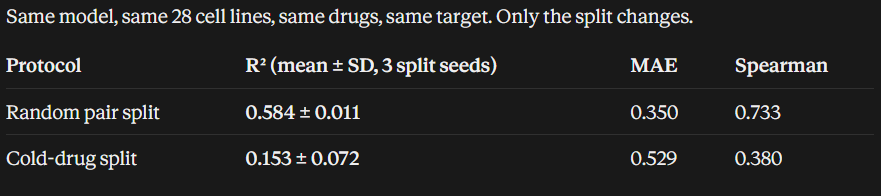

## Results (RF + AE, `y_clip`, mean ± SD over 3 split seeds)

| Protocol | R² | MAE | Spearman |
|---|---|---|---|
| Random pair split | 0.584 ± 0.011 | 0.350 ± 0.006 | 0.733 ± 0.019 |
| Cold-drug split | 0.153 ± 0.072 | 0.529 ± 0.025 | 0.380 ± 0.033 |

Per-seed cold-drug R²: 0.076, 0.219, 0.164. The frozen split used in the main study gave 0.182, inside this range.
Saved to `results/v2/split_comparison.csv`.

## Interpretation

- The protocol alone changes R² from about 0.58 to about 0.15 for the same model and data.
- A likely reason is that in a random split almost every test drug also appears in training with other cell lines.
  Drug identity explains about 76% of the variance in `y_clip` (see the decomposition analysis), so recognising a known
  drug answers most of the question. This is consistent with the data, not directly proven here.
- Cold-drug results vary much more between splits (SD 0.072 vs 0.011), so a single drug split carries real uncertainty.

## Limitations

- Three split seeds per protocol is small; means are indicative.
- The two protocols have different test sets, so this compares protocols, not models.
- Pancreatic-only (28 lines). It does not show that the GraphTCDR paper's own score (402 lines, different target,
  outlier removal) would fall by the same amount; it shows the mechanism is plausible.
- Random splits are not "wrong"; they answer a different question (predicting missing pairs for known drugs).